# Иерархический кластерный анализ

## Цель работы

Выявить структуру сходства между отсканированными изображениями цифр на основе семи бинарных признаков с помощью иерархического кластерного анализа. Определить оптимальное количество кластеров и провести содержательную интерпретацию полученных групп.

## Загрузка и предобработка данных

In [25]:
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [5]:
df = pd.read_csv("digit.dat", sep=";")

In [6]:
# посмотрим на несколько первых записей
df.head()

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2
0,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO
1,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO
2,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO
3,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO
4,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE


In [11]:
df.shape

(500, 16)

Видим, что все столбцы признаков повторяются в данных по два раза. Проверим, действительно ли они идентичны.

In [10]:
pairs = [('A','A2'), ('B','B2'), ('C','C2'), ('D','D2'),
         ('E','E2'), ('F','F2'), ('G','G2'), ('H','H2')]

for c1, c2 in pairs:
    a = df[c1].str.strip()
    b = df[c2].str.strip()

    equal = a.equals(b)
    print(f'{c1} vs {c2}: identical = {equal}')

A vs A2: identical = True
B vs B2: identical = True
C vs C2: identical = True
D vs D2: identical = True
E vs E2: identical = True
F vs F2: identical = True
G vs G2: identical = True
H vs H2: identical = True


Теперь удалим эти столбцы, так как они не несут никакой новой информации

In [12]:
df = df.drop(columns=['A2', 'B2', 'C2', 'D2', 'E2', 'F2', 'G2', 'H2'])

Разделим столбцы на признаки и target (переменную в которой лежит сама цифра)

In [13]:
target = 'A'

X = df.drop(columns=[target])
y = df[target]

Так как проще работать с числами сразу закодируем ONE как 1 и ZERO как 0

In [15]:
# интересно, что ONE написано везде с лишним пробелом
# unique() вывел бы пропуски, если бы они имелись - видим, что пропусков нет
for col in X.columns:
  print(f'{col}: {X[col].unique()}')

B: ['ONE ' 'ZERO']
C: ['ZERO' 'ONE ']
D: ['ONE ' 'ZERO']
E: ['ZERO' 'ONE ']
F: ['ZERO' 'ONE ']
G: ['ONE ' 'ZERO']
H: ['ZERO' 'ONE ']


In [17]:
X = X.replace({'ONE ': 1, 'ZERO': 0}).infer_objects(copy=False)
y = df[target]

## Разбиение на кластеры

Для того чтобы начать иерархический кластерный анализ, необходимо выбрать
- метрику, по которой будем измерять расстояние между точками
- метрику, по которой будем измерять расстояние между кластерами

Было рассмотрено несколько вариантов

### Расстояние между точками

Было рассмотрено несколько метрик, которые потенциально могли бы подойти данной задаче

1. Euclidean (евклидово расстояние)

Это классическое геометрическое расстояние в многомерном пространстве. Для векторов $x = (x_1, \dots, x_p)$ и $y = (y_1, \dots, y_p)$ считается по формуле:  
$$
d_E(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{i=1}^p (x_i - y_i)^2}
$$
Оно минимизирует сумму квадратов отклонений и хорошо работает, когда данные имеют различную шкалу и взаимосвязь (например, координаты в графиках). В нашем случае с бинарными 0/1 признаками может давать большие расстояния при малом различии в линиях.

2. Squared Euclidean (квадрат евклидова расстояния)

То же, что и Euclidean, но без квадратного корня. Это делает расстояния между точками более чувствительными к большим различиям.

3. Cityblock (Manhattan)

Расстояние, где путь измеряется только по горизонталям и вертикалям:  
$$
d_C(\mathbf{x}, \mathbf{y}) = \sum_{i=1}^p |x_i - y_i|
$$
Очень устойчиво к выбросам и шуму. Идеально для данных, где важно общее количество отличий. По сути для данного датасета это то же самое, что и Hamming.

4. Minkowski (обобщённое расстояние)

Обобщение предыдущих метрик:  

$$
d_M(\mathbf{x}, \mathbf{y}) = \left( \sum_{i=1}^p |x_i - y_i|^p \right)^{1/p}
$$

где $p > 0$.

5. Hamming (расстояние Хэмминга)

Для бинарных векторов (как здесь):  
$$
d_H(\mathbf{x}, \mathbf{y}) = \sum_{i=1}^p I(x_i \neq y_i)
$$

где $I$ — индикатор. Максимум — 7 для наших данных. Прямо считает количество линий, которых нет в одной цифре. Это единственная метрика, которая не требует преобразования бинарных признаков в числовые и полностью соответствует номинальной шкале 0/1.

В данных переменные измерены строго в номинальной шкале с значениями 0 и 1 (линия есть/отсутствует). Это классические бинарные признаки без ранга, без пропорциональности и без естественной числовой величины. Hamming — идеально ложится под эти данные: она напрямую считает количество отличающихся позиций (т.е. сколько линий отсутствуют в одной цифре по сравнению с другой), не вводя искусственные веса или преобразования. Другие метрики (Euclidean, Minkowski, Cosine и т.д.) требуют либо числовых данных с разной величиной, либо интервальной шкалы.

### Расстояние между кластерами

1. Average / mean

Объединяет два кластера на основе среднего попарного расстояния между всеми объектами внутри них:  
$$
d_{\text{avg}}(C_i, C_j) = \frac{1}{|C_i| \cdot |C_j|} \sum_{x \in C_i} \sum_{y \in C_j} d(x, y)
$$

Простой, устойчивый метод, не смещает кластеры в одну сторону.

2. Weighted

Взвешенное среднее расстояний:  
$$
d_{\text{weighted}}(C_i, C_j) = \frac{|C_i|}{|C_i| + |C_j|} \, d(C_i, C_i) + \frac{|C_j|}{|C_i| + |C_j|} \, d(C_j, C_j)
$$

Смещает процесс в сторону больших кластеров, что может приводить к асимметричным результатам.

3. Centroid

Объединяет кластеры по расстоянию между их центрами масс (центроидами):  
$$
d_{\text{centroid}}(C_i, C_j) = d\left( \frac{\sum_{x \in C_i} x}{|C_i|}, \frac{\sum_{y \in C_j} y}{|C_j|} \right)
$$

Центры пересчитываются на каждом шаге. Хорошо для плотных кластеров, но менее устойчив к выбросам.

4. Single / nearest neighbor

Объединяет кластеры по минимальному расстоянию между любыми двумя объектами из разных кластеров:  
$$
d_{\text{single}}(C_i, C_j) = \min_{x \in C_i, y \in C_j} d(x, y)
$$
Чувствителен к выбросам и может создавать широкие кластеры с длинными ветвями.

5. Complete / farthest neighbor

Объединяет по максимальному расстоянию между любыми двумя объектами из разных кластеров:  
$$
d_{\text{complete}}(C_i, C_j) = \max_{x \in C_i, y \in C_j} d(x, y)
$$
Более компактные кластеры, но может разрезать настоящие группы.

6. Ward

Объединяет два кластера таким образом, чтобы минимизировать общее внутрикластерное суммарное отклонение (variance):  
$$
\Delta E = \sum_{x \in C_i} \|x - \mu_{C_i}\|^2 + \sum_{y \in C_j} \|y - \mu_{C_j}\|^2 - \sum_{z \in C_{\text{new}}} \|z - \mu_{C_{\text{new}}}\|^2
$$
где $\mu$ — центроид, а расстояние $d$ внутри $\Delta E$ должно быть Euclidean. Кластеры получаются плотными, с минимальной суммарной дисперсией внутри.

Я выбрала average, потому что до этого в для расчета расстояний между точками выбрала hamming. Ward например требует, чтобы расстояние между объектами было строго Euclidean. Однако у average тоже есть плюсы — она совместима с hamming и даёт устойчивые, интерпретируемые кластеры для бинарных данных.

## Построение дендрограммы

Для удобного автоматизированного построения дендограммы я использовала функции `linkage()` и `dendrogram()`.

Функция `linkage()` принимает на вход матрицу данных и автоматически строит последовательность объединений объектов в кластеры.  

Синтаксис:  
```python
Z = linkage(y, metric='...', method='...')
```
где  
- `y` — это исходные данные  
- `metric` — способ расчета расстояния между объектами (`'hamming'` в нашем случае)
- `method` — способ расчета расстояния между кластерами (`'average'` в нашем случае);  
- остальные параметры — вспомогательные.  

`linkage()` возвращает матрицу связей Z размера `(n-1, 4)`:  
- столбец 0 и 1 — индексы двух кластеров, которые объединились,  
- столбец 2 — расстояние, на котором произошло объединение,  
- столбец 3 — размер нового кластера.  

Эта матрица содержит всю информацию о порядке объединений на всех шагах итеративного процесса.

Функция `dendrogram()` — это визуализатор результатов `linkage()`. Она берет матрицу Z и рисует древовидную структуру.

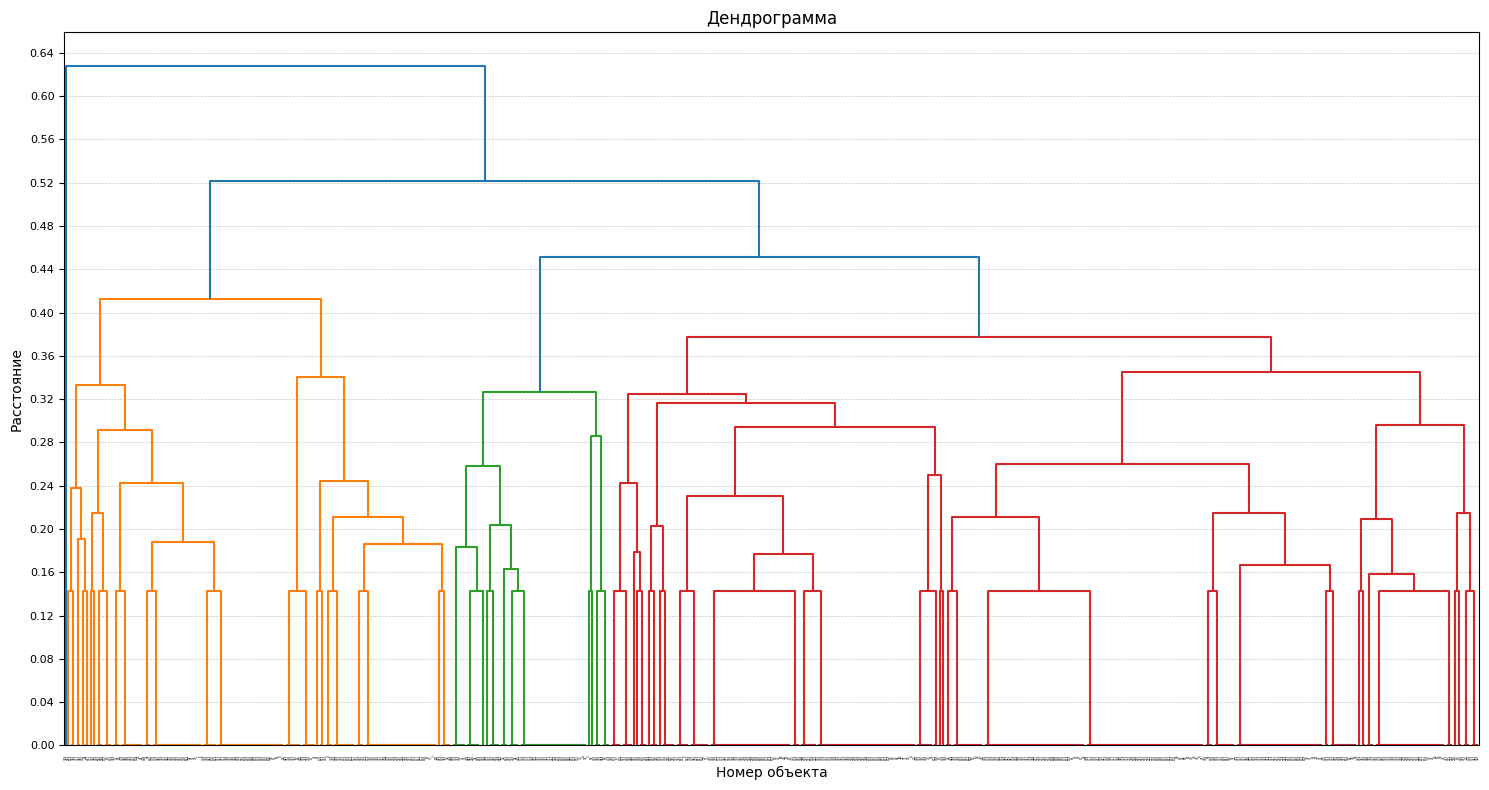

In [29]:
n = len(X)

# 'euclidean', 'sqeuclidean', 'cityblock', 'minkowski', 'hamming', 'cosine', 'correlation', 'seuclidean'
distance_metric = 'hamming'

# 'average', 'weighted', 'centroid', 'single', 'complete', 'median'
linkage_method = 'average'

Z = linkage(X, metric=distance_metric, method=linkage_method)

fig, ax = plt.subplots(figsize=(15, 8))
dendrogram(Z, labels=np.arange(n), leaf_font_size=2, ax=ax)
ax.yaxis.set_major_locator(MaxNLocator(nbins=20))
ax.tick_params(axis='y', labelsize=8)
ax.grid(axis='y', which='major', linestyle='--', linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

ax.set_title('Дендрограмма')
ax.set_xlabel('Номер объекта')
ax.set_ylabel('Расстояние')
plt.tight_layout()
plt.show()

Визуально я считаю, что остановиться нужно на уровне примерно 0.36.

Следующий уровень - 0.40, на нем уже есть длинные горизонтальные линии (в оранжевых и красных кластерах). Это значит, что на одной высоте много объектов объединились на примерно одинаковом расстоянии (почти одновременно) - они образуют один большой, рыхлый кластер. Вероятно, эти объекты не очень похожи.

Также видно, что в самом начале есть один изолированный объект, который объединился в кластер с другими только на самом последнем этапе. Это явный выброс, скорее всего связанный с тем, что отсканирован с ошибкой.

## Результаты кластеризации

Для разрезания уже построенной дендрограммы на конечное число кластеров использовалась функция `fcluster()`  

Синтаксис:  
```python
labels = fcluster(Z, t=<some_number>, criterion='distance')
```  
где  
- `Z` — матрица связей, возвращённая `linkage()`
- `t` — порог (в нашем случае 2.0)
- `criterion` — критерий разрезания

`fcluster()` возвращает одномерный массив `labels` длиной n=500, где для каждого объекта записан номер кластера (от 1 до k)

In [31]:
labels = fcluster(Z, 0.36, criterion='distance')
print(f"Количество кластеров при пороге 0.36: {len(set(labels))}")

for k in range(1, len(set(labels)) + 1):
    cluster_mask = labels == k
    print(f"\nКластер {k} ({np.sum(cluster_mask)} цифр):")
    print("Распределение правильных цифр A:")
    print(pd.Series(y[cluster_mask]).value_counts().sort_index())

Количество кластеров при пороге 0.36: 6

Кластер 1 (77 цифр):
Распределение правильных цифр A:
A
four      4
one      33
seven    37
three     1
zero      2
Name: count, dtype: int64

Кластер 2 (59 цифр):
Распределение правильных цифр A:
A
eight     4
four     37
nine      3
one       9
seven     1
three     4
zero      1
Name: count, dtype: int64

Кластер 3 (56 цифр):
Распределение правильных цифр A:
A
eight     4
five      1
four      3
nine      4
seven     1
three     2
two      40
zero      1
Name: count, dtype: int64

Кластер 4 (118 цифр):
Распределение правильных цифр A:
A
eight     6
five     45
four      4
nine      7
seven     1
six      49
three     3
two       2
zero      1
Name: count, dtype: int64

Кластер 5 (189 цифр):
Распределение правильных цифр A:
A
eight    44
five      8
four      4
nine     41
seven     8
six       1
three    45
two       1
zero     37
Name: count, dtype: int64

Кластер 6 (1 цифр):
Распределение правильных цифр A:
A
one      1
Name: count, dtype: 

In [60]:
outlier_indices = np.where(labels == 6)[0]
outlier_indices[0]

np.int64(348)

In [63]:
def draw_calculator_digit(df: pd.DataFrame, row_index: int) -> None:
    """
    Рисует цифру для строки DataFrame.

    Параметры:
    df : pd.DataFrame
        DataFrame с колонками B–H (0/1).
    row_index : int
        Номер строки в df (или индекс объекта).
    """
    if row_index >= len(df):
        print(f"Ошибка: индекс {row_index} выходит за пределы DataFrame")
        return

    row = df.iloc[row_index].copy()

    fig, ax = plt.subplots(figsize=(4, 6))
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.axis('off')
    ax.set_title(f'Объект {row_index}', fontsize=14)

    ax.plot([0.25, 0.75], [1.0, 1.0], color='white' if row['B'] == 0 else 'black', lw=5)
    ax.plot([0.25, 0.25], [0.5, 1.0], color='white' if row['C'] == 0 else 'black', lw=5)
    ax.plot([0.75, 0.75], [0.5, 1.0], color='white' if row['D'] == 0 else 'black', lw=5)
    ax.plot([0.25, 0.75], [0.5, 0.5], color='white' if row['E'] == 0 else 'black', lw=5)
    ax.plot([0.25, 0.25], [0.0, 0.5], color='white' if row['F'] == 0 else 'black', lw=5)
    ax.plot([0.75, 0.75], [0.0, 0.5], color='white' if row['G'] == 0 else 'black', lw=5)
    ax.plot([0.25, 0.75], [0.0, 0.0], color='white' if row['H'] == 0 else 'black', lw=5)

    plt.show()

Посмотрим на эти цифры - правда ли они похожи на свои метки

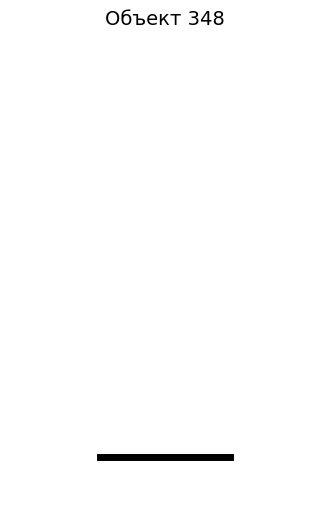

In [64]:
draw_calculator_digit(X, outlier_indices[0])

two  


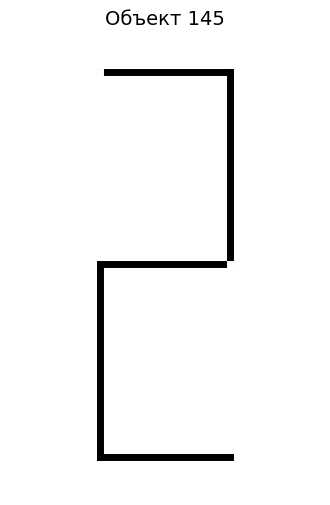

nine 


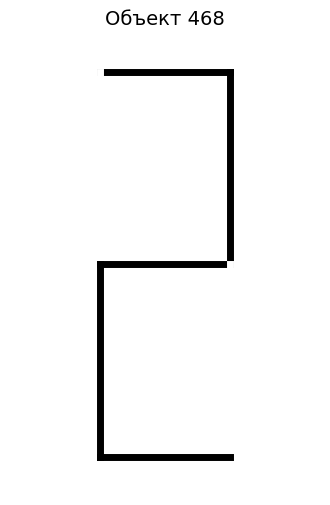

five 


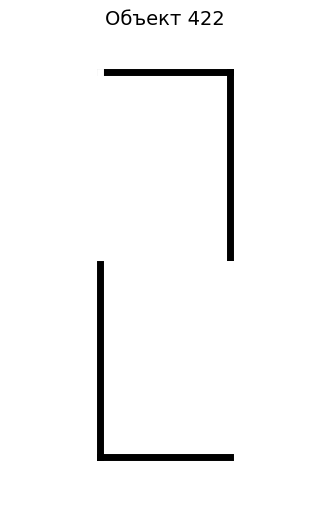

four 


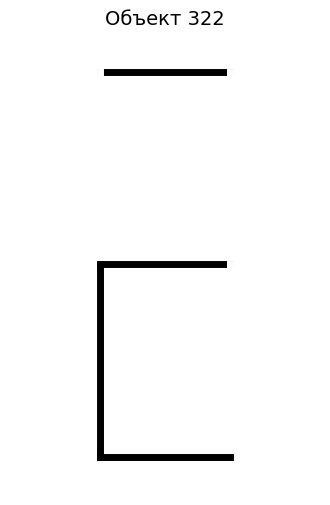

eight


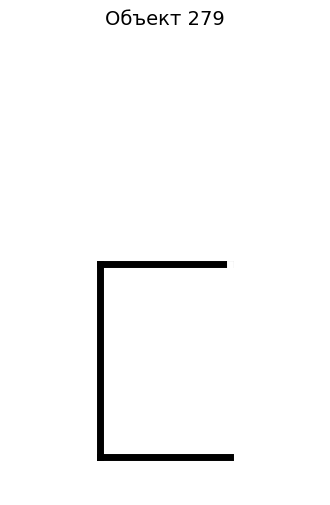

seven


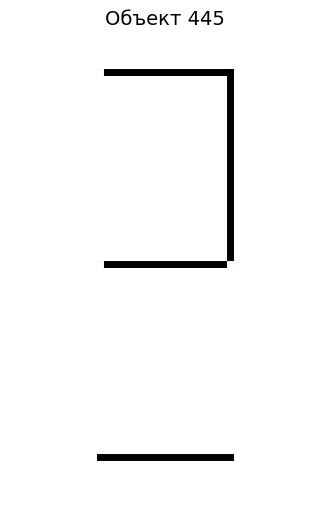

three


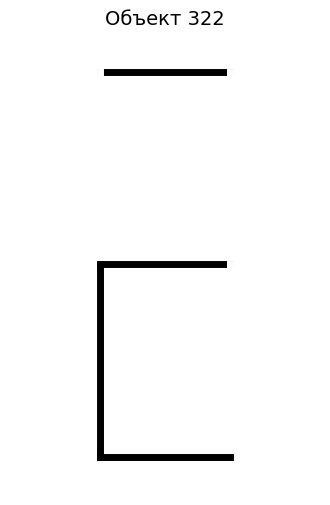

zero 


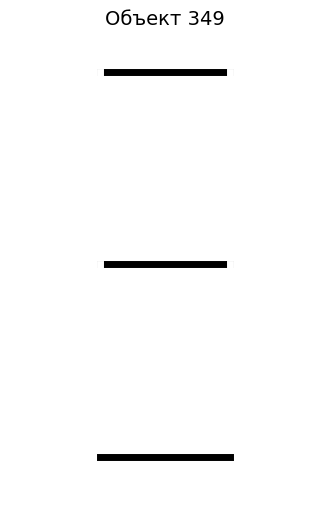

In [69]:
cluster_number = 3
cluster_mask = labels == cluster_number

unique_digits = y[cluster_mask].unique()

for digit in unique_digits:
    print(digit)
    digit_mask = (y[cluster_mask] == digit).index
    random_obj_idx = np.random.choice(digit_mask)

    draw_calculator_digit(X, random_obj_idx)

seven


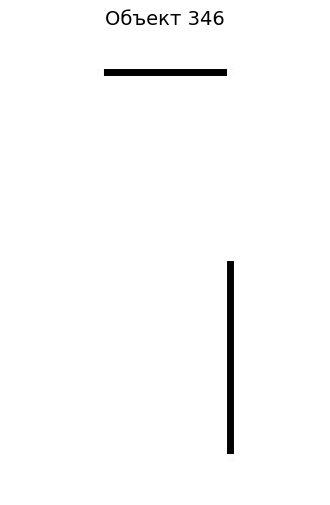

one  


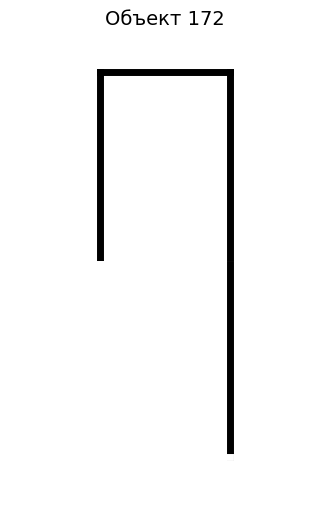

zero 


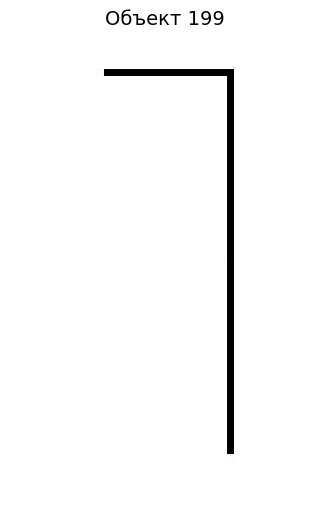

four 


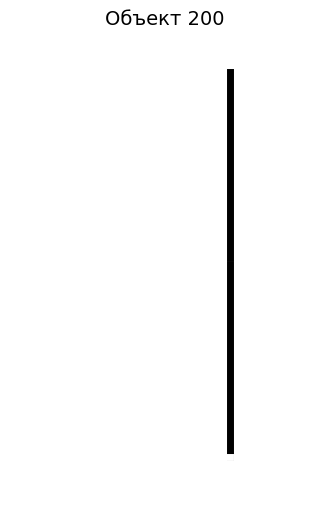

three


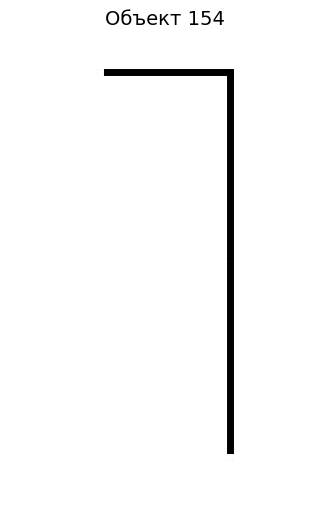

In [70]:
cluster_number = 1
cluster_mask = labels == cluster_number

unique_digits = y[cluster_mask].unique()

for digit in unique_digits:
    print(digit)
    digit_mask = (y[cluster_mask] == digit).index
    random_obj_idx = np.random.choice(digit_mask)

    draw_calculator_digit(X, random_obj_idx)

# Выводы

Результаты кластеризации позволили выделить шесть групп. Результаты кластеризации показывают, что цифры действительно группируются по визуальному сходству. Например, в первом кластере преобладают цифры 1 и 7, во втором — цифра 4, в третьем — цифра 2, в четвертом — цифры 5 и 6, пятый кластер объединяет цифры 3, 8, 9 и 0. Все группы имеют определенные общие визуальные характеристики.

Отдельно стоит отметить шестой кластер, состоящий всего из одной цифры 1. Вероятнее всего, это выброс, возникший из-за плохого качества сканирования.